# Phase 5: YOLO Segmentation (Comparison)

Train a YOLO segmentation model (Ultralytics **YOLO11s-seg**) on the **same train / val / test split** as the U-Net, then compare the two.

YOLO finds each lesion as a separate object with a **box**, a **mask** and a **confidence score**. We use one class, `lesion`, so YOLO answers *is there a tumour, how many, where and how big*. Benign vs malignant comes from the classifier or the multi-task U-Net.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output** (saved to `outputs/yolo/`):

| File | What it contains |
| ---- | ---------------- |
| `dataset/` | The data converted to YOLO format (images, polygon labels, `data.yaml`) |
| `model.pt` | Trained YOLO weights (best epoch) |
| `config.json` | Image size, **tuned confidence threshold, mask cleanup** and training settings |
| `history.csv` | Losses and mAP for every epoch |
| `metrics.json` | Test results (v2): mAP, Dice, IoU, false and missed lesions, with 95% confidence ranges |
| `metrics_v1_vs_v2.csv` | v1 and v2 test results side by side |
| `test_predictions.csv` | Detections, Dice and lesion area (v1 and v2) for every test image |
| `masks/` | Predicted mask (v2) for every test image, at the original size (same format as U-Net, for `04_measure`) |
| `threshold_tuning.png` | Confidence threshold tuning on the validation set |
| `train/`, `test/` | YOLO's own plots (results, PR curves, confusion matrix, sample batches) |
| `training_curves.png`, `prediction_examples.png`, `worst_predictions.png` | Our result plots |
| `../model_comparison.csv` | Classifier vs U-Net vs YOLO, side by side |

**Before the first run:** install Ultralytics with `.env/bin/pip install ultralytics`. The pretrained weights (`yolo11s-seg.pt`, about 20 MB) download automatically the first time.

> **Licence:** Ultralytics YOLO is AGPL-3.0. That's fine for learning and research; commercial use needs an Ultralytics licence.

---

### v2 changes

| Change | Why |
| ------ | --- |
| `TRAIN` setting: `False` reuses the trained v1 model | Fixes are measured on the **same model**, so any change in the scores comes from the fix, not from training randomness |
| **Confidence threshold tuned on the validation set** | v1 used YOLO's default 0.25 and drew a lesion on 41% of normal scans, mostly with low confidence (0.26–0.37) |
| **Mask cleanup:** fill holes, drop regions smaller than `MIN_REGION_PCT` % of the image (same as the U-Net) | Removed 6 false lesions from the U-Net without losing real ones |
| **95% confidence ranges** (bootstrap) and v1 vs v2 side by side | The test set is small, so we need to see how much of a change is luck |

Mask **smoothing** (added to the U-Net in v2) isn't needed here: YOLO already builds its masks at the original image size (`retina_masks=True`).

The v1 results are archived in `outputs/archive/v1_baseline/` and git tag `v1-baseline`.

## 1. Imports

In [1]:
import json
import shutil
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from PIL import Image
from scipy import ndimage                     # v2: hole filling and region sizes for mask cleanup
from skimage.measure import label, regionprops, find_contours, approximate_polygon
from ultralytics import YOLO

## 2. Settings

In [2]:
DATA_DIR = Path('data')
YOLO_DIR = Path('outputs/yolo')            # everything for this model is saved here
DATASET_DIR = YOLO_DIR / 'dataset'         # data converted to YOLO format
MASK_DIR = YOLO_DIR / 'masks'              # predicted test masks
YOLO_DIR.mkdir(parents=True, exist_ok=True)

PRETRAINED = 'yolo11s-seg.pt'   # small YOLO11 segmentation model, pretrained on COCO
IMAGE_SIZE = 640                # YOLO's standard input size (images are padded to a square)
BATCH_SIZE = 8
EPOCHS = 100                    # maximum; training can stop earlier
PATIENCE = 20                   # stop if validation hasn't improved for this many epochs
CONF_THRESHOLD = 0.25           # v1: detections below this confidence are ignored (YOLO's default)
MIN_LESION_PIXELS = 50          # same as the other notebooks: smaller regions are noise
RANDOM_STATE = 42

TRAIN = False                   # v2: False = reuse the saved model.pt, True = train a new model
TUNE_CONF = True                # v2: tune the confidence threshold on the validation set
CLEAN_MASKS = True              # v2: fill holes and drop small regions in predicted masks (same as the U-Net)
MIN_REGION_PCT = 0.2            # v2: regions smaller than this % of the image are dropped (smallest real lesion is ~0.3%)
N_BOOTSTRAP = 1000              # v2: resamples used for the 95% confidence ranges

DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'   # Apple GPU if available
print('Using device:', DEVICE, '| Train a new model:', TRAIN)

manifest = pd.read_csv(DATA_DIR / 'manifest.csv')
val_df = manifest[manifest['split'] == 'val'].reset_index(drop=True)      # v2: used to tune the threshold
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
print(manifest['split'].value_counts().to_string())

Using device: mps | Train a new model: False
split
train    485
test     104
val      104


## 3. Convert the data to YOLO format

YOLO needs a specific folder layout, with one text file of labels per image:

```
dataset/
├── images/train/benign_12.png     ├── labels/train/benign_12.txt
├── images/val/...                 ├── labels/val/...
├── images/test/...                ├── labels/test/...
└── data.yaml                      (where the folders are + class names)
```

Each line of a label file is one lesion: `0 x1 y1 x2 y2 ...`. `0` is the class (`lesion`) and the numbers are the corners of its **outline polygon**, divided by the image width / height so they go from 0 to 1.

To get the polygon, we trace the outline of each separate lesion in the mask and simplify it to fewer points. **Normal** images get an **empty** label file: this teaches YOLO that some scans contain nothing.

Files are renamed without spaces or brackets (`benign (12).png` becomes `benign_12.png`), and the same split as the manifest is used.

In [3]:
def load_true_mask(mask_paths):
    """Merge an image's ground-truth masks into one True/False array."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return np.any(masks, axis=0)


def mask_to_polygons(mask):
    """Outline of each separate lesion in a True/False mask, as a list of polygons [(x, y), ...] in pixels."""
    polygons = []
    labelled = label(mask, connectivity=2)                       # number each separate region
    for region in regionprops(labelled):
        if region.area < MIN_LESION_PIXELS:
            continue                                             # skip tiny specks
        lesion = np.pad(labelled == region.label, 1)             # 1-pixel border so outlines at the edge close
        outline = max(find_contours(lesion.astype(float), 0.5), key=len)    # outer outline = longest contour
        outline = approximate_polygon(outline, tolerance=1.0) - 1          # fewer points, undo the border
        polygons.append([(x, y) for y, x in outline])                      # (row, col) -> (x, y)
    return polygons


def polygon_to_label(polygon, width, height):
    """One YOLO label line: class 0, then x y pairs scaled to 0..1."""
    coords = ' '.join(f'{np.clip(x / width, 0, 1):.5f} {np.clip(y / height, 0, 1):.5f}' for x, y in polygon)
    return f'0 {coords}'


def yolo_name(image_path):
    """'benign/benign (12).png' -> 'benign_12' (no spaces or brackets)."""
    return Path(image_path).stem.replace(' (', '_').replace(')', '')

In [4]:
for folder in ['images', 'labels']:
    for split in ['train', 'val', 'test']:
        (DATASET_DIR / folder / split).mkdir(parents=True, exist_ok=True)

n_polygons = 0
for row in manifest.itertuples():
    name = yolo_name(row.image_path)
    shutil.copy(DATA_DIR / row.image_path, DATASET_DIR / 'images' / row.split / f'{name}.png')

    mask = load_true_mask(row.mask_paths)
    height, width = mask.shape
    lines = [polygon_to_label(p, width, height) for p in mask_to_polygons(mask)]   # empty for normal images
    (DATASET_DIR / 'labels' / row.split / f'{name}.txt').write_text('\n'.join(lines))
    n_polygons += len(lines)

# Tell YOLO where the data is and what the classes are
data_yaml = DATASET_DIR / 'data.yaml'
data_yaml.write_text(
    f"path: '{DATASET_DIR.resolve()}'\n"
    'train: images/train\n'
    'val: images/val\n'
    'test: images/test\n'
    'names:\n'
    '  0: lesion\n'
)
print(f'Converted {len(manifest)} images with {n_polygons} lesion outlines')
print(data_yaml.read_text())

Converted 693 images with 595 lesion outlines
path: '/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset'
train: images/train
val: images/val
test: images/test
names:
  0: lesion



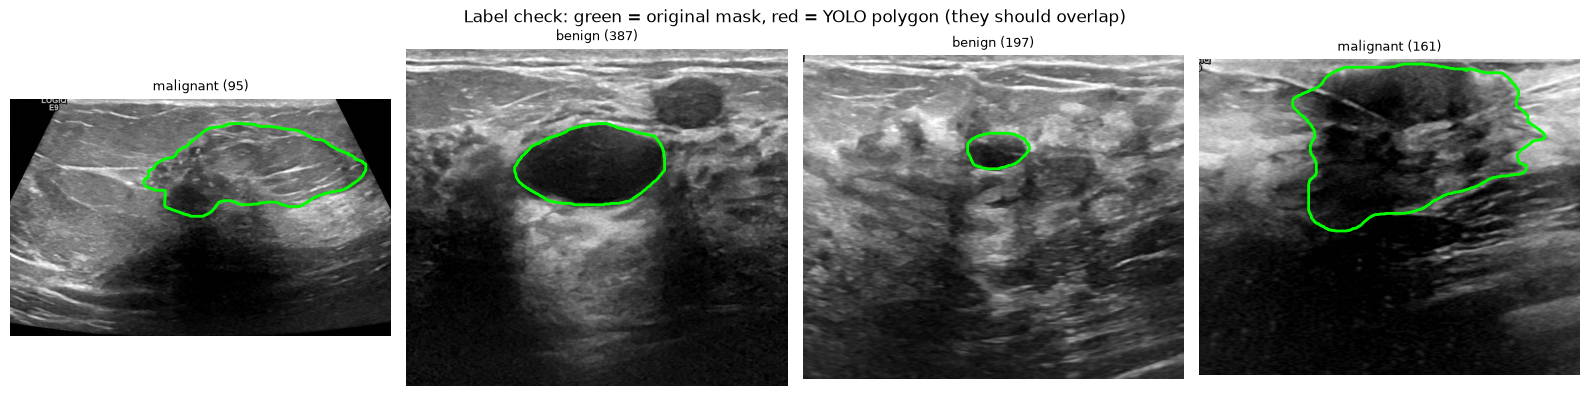

In [5]:
# Check the conversion: draw the YOLO polygons (red) over the original masks (green)
samples = manifest[manifest['label'] != 'normal'].sample(4, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, row in zip(axes, samples.itertuples()):
    image = Image.open(DATA_DIR / row.image_path).convert('L')
    width, height = image.size
    ax.imshow(image, cmap='gray')
    ax.contour(load_true_mask(row.mask_paths), levels=[0.5], colors='lime', linewidths=2)

    label_file = DATASET_DIR / 'labels' / row.split / f'{yolo_name(row.image_path)}.txt'
    for line in label_file.read_text().splitlines():
        values = np.array(line.split()[1:], dtype=float).reshape(-1, 2) * [width, height]   # back to pixels
        ax.add_patch(patches.Polygon(values, fill=False, edgecolor='red', linewidth=1.2))
    ax.set_title(Path(row.image_path).stem, fontsize=9)
    ax.axis('off')

plt.suptitle('Label check: green = original mask, red = YOLO polygon (they should overlap)')
plt.tight_layout()
plt.show()

## 4. Train

We fine-tune a YOLO11s-seg model pretrained on the COCO dataset. Ultralytics handles augmentation, validation after each epoch, early stopping and saving the best weights.

We change only the augmentations that matter for ultrasound:
- `flipud=0.0`: never flip up-down, because the skin is always at the top
- `fliplr=0.5`: left-right flips are fine
- `degrees=10`: small rotations, the same as the U-Net

**v2:** with `TRAIN = False`, training is skipped and the saved `model.pt` and `history.csv` from the previous run are reused.

In [6]:
if TRAIN:
    model = YOLO(PRETRAINED)                     # downloads the pretrained weights the first time
    model.train(
        data=str(data_yaml),
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        seed=RANDOM_STATE,
        project=str(YOLO_DIR.resolve()),         # save YOLO's run inside outputs/yolo/
        name='train',
        exist_ok=True,                           # overwrite the previous run
        flipud=0.0,                              # no up-down flips
        fliplr=0.5,                              # left-right flips half the time
        degrees=10,                              # small rotations
    )
else:
    # v2: reuse the previous run's model and settings (nothing is retrained)
    previous_config = json.loads((YOLO_DIR / 'config.json').read_text())
    print(f"Skipping training: reusing {YOLO_DIR}/model.pt (best epoch {previous_config['best_epoch']}, "
          f"trained on {previous_config['trained_on']})")

Skipping training: reusing outputs/yolo/model.pt (best epoch 60, trained on 2026-11-11 00:54)


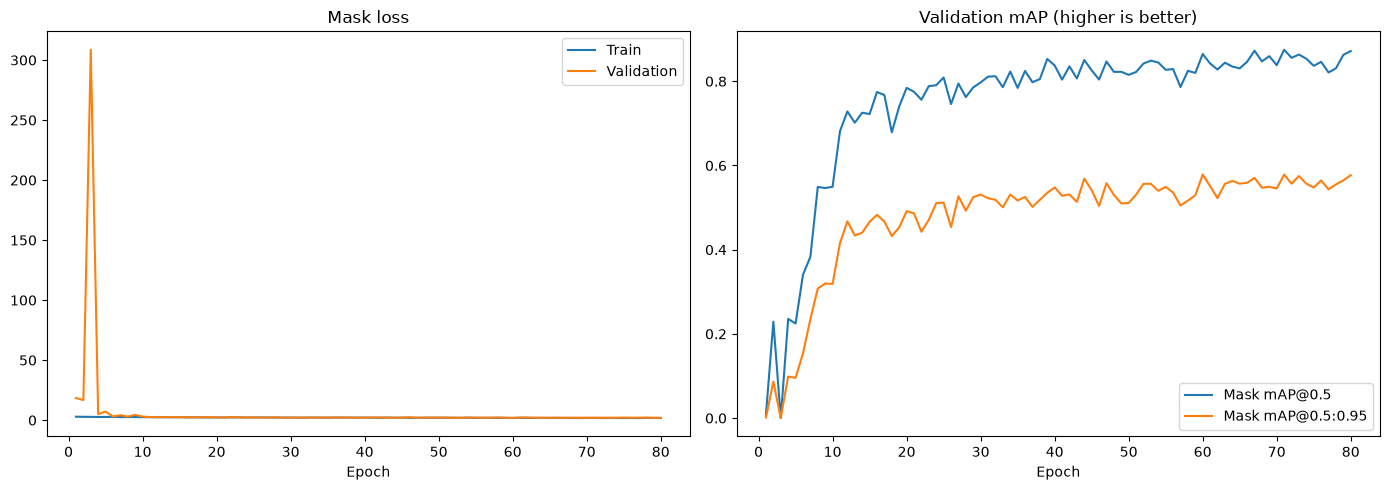

In [7]:
TRAIN_DIR = YOLO_DIR / 'train'
if TRAIN:
    shutil.copy(TRAIN_DIR / 'weights' / 'best.pt', YOLO_DIR / 'model.pt')     # same file name as the other models
    history = pd.read_csv(TRAIN_DIR / 'results.csv')
    history.columns = history.columns.str.strip()                             # YOLO pads column names with spaces
    history.to_csv(YOLO_DIR / 'history.csv', index=False)
else:
    history = pd.read_csv(YOLO_DIR / 'history.csv')                           # v2: reuse the saved history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['epoch'], history['train/seg_loss'], label='Train')
axes[0].plot(history['epoch'], history['val/seg_loss'], label='Validation')
axes[0].set_title('Mask loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['epoch'], history['metrics/mAP50(M)'], label='Mask mAP@0.5')
axes[1].plot(history['epoch'], history['metrics/mAP50-95(M)'], label='Mask mAP@0.5:0.95')
axes[1].set_title('Validation mAP (higher is better)')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig(YOLO_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Evaluate on the test set

### YOLO's own metric: mAP

**mAP** (mean average precision) is the standard score for detection models. It measures how well the predicted lesions match the true ones across all confidence levels.
- **mAP@0.5:** a lesion counts as found if its overlap with the true one is at least 50%.
- **mAP@0.5:0.95:** the average over stricter overlaps (50% up to 95%). This is a harder, more precise score.

We report it for both the **masks** and the **boxes**.

In [8]:
best_model = YOLO(YOLO_DIR / 'model.pt')
test_scores = best_model.val(data=str(data_yaml), split='test', imgsz=IMAGE_SIZE, device=DEVICE,
                             project=str(YOLO_DIR.resolve()), name='test', exist_ok=True)

metrics = {
    'mask_map50': float(test_scores.seg.map50),
    'mask_map50_95': float(test_scores.seg.map),
    'box_map50': float(test_scores.box.map50),
    'box_map50_95': float(test_scores.box.map),
}
metrics

Ultralytics 8.4.209 🚀 Python-3.14.4 torch-2.15.0 MPS (Apple M5)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3460.4±3656.1 MB/s, size: 425.4 KB)
val: Scanning /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset/labels/test... 104 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 104/104 1.9Kit/s 0.1s
val: New cache created: /Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/ultrasonic_scans/outputs/yolo/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.4it/s 5.1s0.6ss
                   all        104         88      0.848      0.823       0.88      0.602      0.848      0.823      0.881      0.613
Speed: 0.3ms preprocess, 14.7ms inference, 0.0ms loss, 22.7ms postprocess per image
Results saved to /Us

{'mask_map50': 0.8811024888649174,
 'mask_map50_95': 0.6132564378659405,
 'box_map50': 0.8798879138116094,
 'box_map50_95': 0.602052719169814}

### The same scores as the U-Net

To compare fairly, we turn YOLO's detections into one mask per image, **at the original image size**, exactly like the U-Net's saved masks. Then we compute the same Dice and IoU, and count false and missed lesions. The masks are saved to `masks/` so `04_measure` can measure them too.

**v2:** YOLO runs **once** per image and every detection (confidence, box, mask) is kept. Building the final mask is a separate step, so different settings can be tried without running the model again:

| Step | v1 | v2 |
| ---- | -- | -- |
| 1. Keep detections | Confidence ≥ 0.25 (YOLO's default) | Confidence ≥ the threshold **tuned on the validation set** |
| 2. Merge | All kept detections into one mask | Same |
| 3. Cleanup | None | Fill holes; drop regions smaller than `MIN_REGION_PCT` % of the image |

In [9]:
def detect(net, image, min_conf=CONF_THRESHOLD, image_size=IMAGE_SIZE, device=DEVICE):
    """v2: run YOLO once on a PIL image. Returns every detection with confidence >= min_conf
    (confidence, box and its own True/False mask at the original size) and the image shape."""
    width, height = image.size
    result = net.predict(image.convert('RGB'), imgsz=image_size, conf=min_conf, retina_masks=True,
                         device=device, verbose=False)[0]
    found = []
    if result.masks is not None:                                     # None when nothing was found
        lesion_masks = result.masks.data.cpu().numpy()
        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        for lesion, box, score in zip(lesion_masks, boxes, scores):
            lesion = lesion > 0.5
            if lesion.shape != (height, width):                      # safety: resize to the original size
                lesion = np.array(Image.fromarray(lesion.astype(np.uint8) * 255)
                                  .resize((width, height), Image.NEAREST)) > 127
            found.append({'confidence': float(score), 'box': [round(float(v), 1) for v in box], 'mask': lesion})
    return found, (height, width)


def clean_mask(mask, min_region_pct=MIN_REGION_PCT, min_pixels=MIN_LESION_PIXELS):
    """v2: fill holes inside lesions, then drop regions smaller than min_region_pct % of the image."""
    filled = ndimage.binary_fill_holes(mask)
    labelled, n_regions = ndimage.label(filled, structure=np.ones((3, 3)))     # number each separate region
    sizes = ndimage.sum(filled, labelled, range(1, n_regions + 1))             # pixels in each region
    min_size = max(min_pixels, mask.size * min_region_pct / 100)
    keep = [number for number, size in enumerate(sizes, start=1) if size >= min_size]
    return np.isin(labelled, keep)


def combine(found, shape, conf, clean):
    """v2: merge the detections with confidence >= conf into one mask (optionally cleaned).
    Returns (mask, kept detections without their masks)."""
    mask = np.zeros(shape, dtype=bool)
    kept = []
    for detection in found:
        if detection['confidence'] >= conf:
            mask |= detection['mask']
            kept.append({'confidence': round(detection['confidence'], 3), 'box': detection['box']})
    return (clean_mask(mask) if clean else mask), kept


def predict_mask(net, image, conf=CONF_THRESHOLD, image_size=IMAGE_SIZE, device=DEVICE, clean=False):
    """Run YOLO on one PIL image. Returns (True/False mask at the original size, list of detections)."""
    found, shape = detect(net, image, conf, image_size, device)
    return combine(found, shape, conf, clean)


def dice_score(pred, truth):
    """Overlap of two True/False masks: 1 = identical, 0 = no overlap."""
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else float(2 * (pred & truth).sum() / total)


def iou_score(pred, truth):
    """Intersection over union of two True/False masks: 1 = identical, 0 = no overlap."""
    union = (pred | truth).sum()
    return 1.0 if union == 0 else float((pred & truth).sum() / union)

### v2: tune the confidence threshold on the validation set

For each confidence threshold from 0.25 to 0.90 we count, on the validation set:
- **normal scans with a false lesion** (should go down as the threshold rises),
- **tumour scans with no lesion** (may go up if the threshold gets too strict).

We pick the **highest** threshold that doesn't leave any extra tumour scan without a lesion compared with v1's 0.25. That removes as many low-confidence false lesions as possible without hiding real tumours.

**Caveat:** YOLO also used the validation set to pick its best epoch, so it may look slightly better on validation than on the test set (we saw this with the U-Net).

Validation, confidence >= 0.25: false lesion on 23.5% of normal scans, no lesion found on 10.3% of tumour scans
Chosen confidence threshold: 0.25


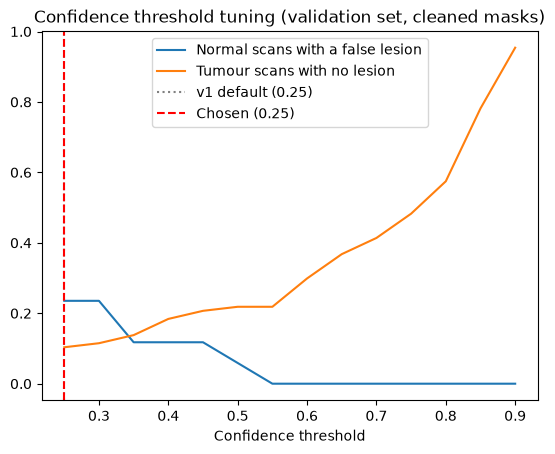

In [10]:
# v2: run YOLO once on every validation image, keeping all detections with confidence >= 0.25
val_found = [detect(best_model, Image.open(DATA_DIR / row.image_path)) for row in val_df.itertuples()]
val_tumour = (val_df['label'] != 'normal').values

rows = []
for conf in np.round(np.arange(0.25, 0.91, 0.05), 2):
    has_lesion = np.array([combine(found, shape, conf, CLEAN_MASKS)[0].sum() >= MIN_LESION_PIXELS
                           for found, shape in val_found])
    rows.append({'conf': conf,
                 'false_lesion_normal': has_lesion[~val_tumour].mean(),     # normal scans with a lesion drawn
                 'tumour_missed': (~has_lesion[val_tumour]).mean()})       # tumour scans with no lesion
tuning = pd.DataFrame(rows)

# Highest threshold that doesn't leave any extra tumour scan without a lesion (compared with 0.25)
missed_at_default = tuning.loc[tuning['conf'] == CONF_THRESHOLD, 'tumour_missed'].iloc[0]
safe = tuning[tuning['tumour_missed'] <= missed_at_default + 1e-9]
CONF_THRESHOLD_V2 = float(safe['conf'].max()) if TUNE_CONF else CONF_THRESHOLD

for conf in sorted({CONF_THRESHOLD, CONF_THRESHOLD_V2}):
    row = tuning[tuning['conf'] == conf].iloc[0]
    print(f"Validation, confidence >= {conf:.2f}: false lesion on {row['false_lesion_normal']:.1%} of normal scans, "
          f"no lesion found on {row['tumour_missed']:.1%} of tumour scans")
print(f'Chosen confidence threshold: {CONF_THRESHOLD_V2:.2f}')

plt.plot(tuning['conf'], tuning['false_lesion_normal'], label='Normal scans with a false lesion')
plt.plot(tuning['conf'], tuning['tumour_missed'], label='Tumour scans with no lesion')
plt.axvline(CONF_THRESHOLD, color='grey', linestyle=':', label=f'v1 default ({CONF_THRESHOLD:.2f})')
plt.axvline(CONF_THRESHOLD_V2, color='red', linestyle='--', label=f'Chosen ({CONF_THRESHOLD_V2:.2f})')
plt.xlabel('Confidence threshold')
plt.title('Confidence threshold tuning (validation set, cleaned masks)')
plt.legend()
plt.savefig(YOLO_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
plt.show()

In [11]:
rows, all_detections = [], {}
for row in test_df.itertuples():
    found, shape = detect(best_model, Image.open(DATA_DIR / row.image_path))    # run YOLO once
    truth = load_true_mask(row.mask_paths)
    raw, kept_v1 = combine(found, shape, CONF_THRESHOLD, clean=False)            # v1: confidence >= 0.25, no cleanup
    pred, kept = combine(found, shape, CONF_THRESHOLD_V2, clean=CLEAN_MASKS)    # v2: tuned threshold + cleanup
    all_detections[row.image_path] = kept

    mask_path = MASK_DIR / row.image_path                       # same layout as the U-Net masks
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(pred.astype(np.uint8) * 255).save(mask_path)   # v2 mask, used by 04_measure

    rows.append({
        'image_path': row.image_path,
        'label': row.label,
        'has_markers': row.has_markers,
        'pred_mask_path': str(mask_path.relative_to(YOLO_DIR)),
        'n_detections_v1': len(kept_v1),            # v2: keep the v1 results for comparison
        'tumour_detected_v1': len(kept_v1) > 0,
        'dice_v1': dice_score(raw, truth),
        'iou_v1': iou_score(raw, truth),
        'pred_area_px_v1': int(raw.sum()),
        'n_detections': len(kept),
        'max_confidence': max((d['confidence'] for d in kept), default=0.0),
        'tumour_detected': int(pred.sum()) >= MIN_LESION_PIXELS,   # v2: a lesion is left after cleanup
        'dice': dice_score(pred, truth),
        'iou': iou_score(pred, truth),
        'true_area_px': int(truth.sum()),
        'pred_area_px': int(pred.sum()),
    })

results = pd.DataFrame(rows)
results.to_csv(YOLO_DIR / 'test_predictions.csv', index=False)
print(f'Saved {len(results)} predicted masks to {MASK_DIR}')
results.head()

Saved 104 predicted masks to outputs/yolo/masks


,image_path,label,has_markers,pred_mask_path,n_detections_v1,tumour_detected_v1,dice_v1,iou_v1,pred_area_px_v1,n_detections,max_confidence,tumour_detected,dice,iou,true_area_px,pred_area_px
0,normal/normal (103).png,normal,False,masks/normal/normal (103).png,1,True,0.0,0.0,23088,1,0.368,True,0.0,0.0,0,23088
1,normal/normal (108).png,normal,True,masks/normal/normal (108).png,1,True,0.0,0.0,16126,1,0.297,True,0.0,0.0,0,16126
2,normal/normal (114).png,normal,True,masks/normal/normal (114).png,0,False,1.0,1.0,0,0,0.000,False,1.0,1.0,0,0
3,normal/normal (115).png,normal,False,masks/normal/normal (115).png,0,False,1.0,1.0,0,0,0.000,False,1.0,1.0,0,0
4,normal/normal (120).png,normal,False,masks/normal/normal (120).png,0,False,1.0,1.0,0,0,0.000,False,1.0,1.0,0,0


In [12]:
tumour = results['label'] != 'normal'


def compute_metrics(frame, version='v2'):
    """All test scores for one version: 'v1' (confidence >= 0.25, no cleanup) or 'v2' (tuned threshold + cleanup)."""
    s = '_v1' if version == 'v1' else ''
    label = frame['label'].values
    is_tumour_img = label != 'normal'
    dice, iou = frame['dice' + s].values, frame['iou' + s].values
    has_lesion = frame['pred_area_px' + s].values >= MIN_LESION_PIXELS
    detected = frame['tumour_detected' + s].values.astype(bool)
    return {
        # Outline quality (tumour images only, like the U-Net)
        'dice_tumour_images': float(dice[is_tumour_img].mean()),
        'iou_tumour_images': float(iou[is_tumour_img].mean()),
        'dice_benign': float(dice[label == 'benign'].mean()),
        'dice_malignant': float(dice[label == 'malignant'].mean()),
        # False and missed lesions
        'normal_images_with_false_lesion': float(has_lesion[~is_tumour_img].mean()),
        'tumour_images_with_no_lesion_found': float((~has_lesion[is_tumour_img]).mean()),
        # Tumour or not
        'tumour_sensitivity': float(detected[is_tumour_img].mean()),
        'tumour_specificity': float((~detected[~is_tumour_img]).mean()),
    }


metrics_v1 = compute_metrics(results, 'v1')
metrics_v2 = compute_metrics(results, 'v2')

print(f"{'':36s} {'v1':>7s} {'v2':>7s}")
for name in metrics_v2:
    print(f'{name:36s} {metrics_v1[name]:7.3f} {metrics_v2[name]:7.3f}')

# v2: sanity check - v1 here should match the archived v1 run (same model, same scoring)
archived = Path('outputs/archive/v1_baseline/yolo/metrics.json')
if archived.exists():
    old = json.loads(archived.read_text())
    same = all(abs(old[k] - metrics_v1[k]) < 1e-6 for k in metrics_v1 if k in old)
    print('\nv1 matches the archived v1 results:', same)

                                          v1      v2
dice_tumour_images                     0.751   0.750
iou_tumour_images                      0.679   0.679
dice_benign                            0.777   0.777
dice_malignant                         0.701   0.701
normal_images_with_false_lesion        0.412   0.412
tumour_images_with_no_lesion_found     0.103   0.103
tumour_sensitivity                     0.897   0.897
tumour_specificity                     0.588   0.588

v1 matches the archived v1 results: True


### v2: v1 vs v2 with 95% confidence ranges

We **bootstrap**: draw 1,000 new test sets of the same size by picking test images at random (with replacement), score each one, and keep the middle 95% of the scores.

**How to read it:** if the v1 and v2 ranges overlap a lot, the difference may just be luck. A change that moves the value well outside the other version's range is a real improvement.

YOLO's **mAP** (section 5) isn't affected by the threshold or cleanup: it's measured over all confidence levels.

In [13]:
def confidence_range(frame, version, n=N_BOOTSTRAP):
    """95% range of every score: re-draw the test set n times (same size, with replacement) and re-score it."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = [compute_metrics(frame.iloc[rng.integers(0, len(frame), size=len(frame))], version) for _ in range(n)]
    scores = pd.DataFrame(scores)
    return scores.quantile(0.025), scores.quantile(0.975)


v1_low, v1_high = confidence_range(results, 'v1')
v2_low, v2_high = confidence_range(results, 'v2')

comparison = pd.DataFrame({
    'v1': [metrics_v1[k] for k in metrics_v2],
    'v1 95% range': [f'{v1_low[k]:.3f} - {v1_high[k]:.3f}' for k in metrics_v2],
    'v2': [metrics_v2[k] for k in metrics_v2],
    'v2 95% range': [f'{v2_low[k]:.3f} - {v2_high[k]:.3f}' for k in metrics_v2],
}, index=list(metrics_v2)).round(3)
comparison.to_csv(YOLO_DIR / 'metrics_v1_vs_v2.csv')

# Save the v2 results: YOLO's mAP (from section 5) + the scores above + ranges + settings
metrics.update(metrics_v2)
metrics['confidence_95'] = {k: [round(float(v2_low[k]), 4), round(float(v2_high[k]), 4)] for k in metrics_v2}

# Shortcut check: outline quality on images with vs without markers
marker_check = results[tumour].groupby('has_markers')['dice'].agg(dice='mean', images='count')
metrics['dice_with_markers'] = float(marker_check['dice'].get(True, float('nan')))
metrics['dice_without_markers'] = float(marker_check['dice'].get(False, float('nan')))
metrics['conf_threshold'] = CONF_THRESHOLD_V2          # v2: the settings these results were produced with
metrics['clean_masks'] = CLEAN_MASKS
metrics['test_images'] = int(len(results))

(YOLO_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))
comparison

,v1,v1 95% range,v2,v2 95% range
dice_tumour_images,0.751,0.682 - 0.817,0.750,0.682 - 0.817
iou_tumour_images,0.679,0.615 - 0.742,0.679,0.615 - 0.742
dice_benign,0.777,0.688 - 0.857,0.777,0.688 - 0.857
dice_malignant,0.701,0.589 - 0.809,0.701,0.589 - 0.808
normal_images_with_false_lesion,0.412,0.176 - 0.667,0.412,0.176 - 0.667
tumour_images_with_no_lesion_found,0.103,0.044 - 0.167,0.103,0.044 - 0.167
tumour_sensitivity,0.897,0.833 - 0.956,0.897,0.833 - 0.956
tumour_specificity,0.588,0.333 - 0.824,0.588,0.333 - 0.824


## 6. See the predictions

**Green** = true outline, **red** = YOLO's mask, **yellow box** = YOLO's detection with its confidence.

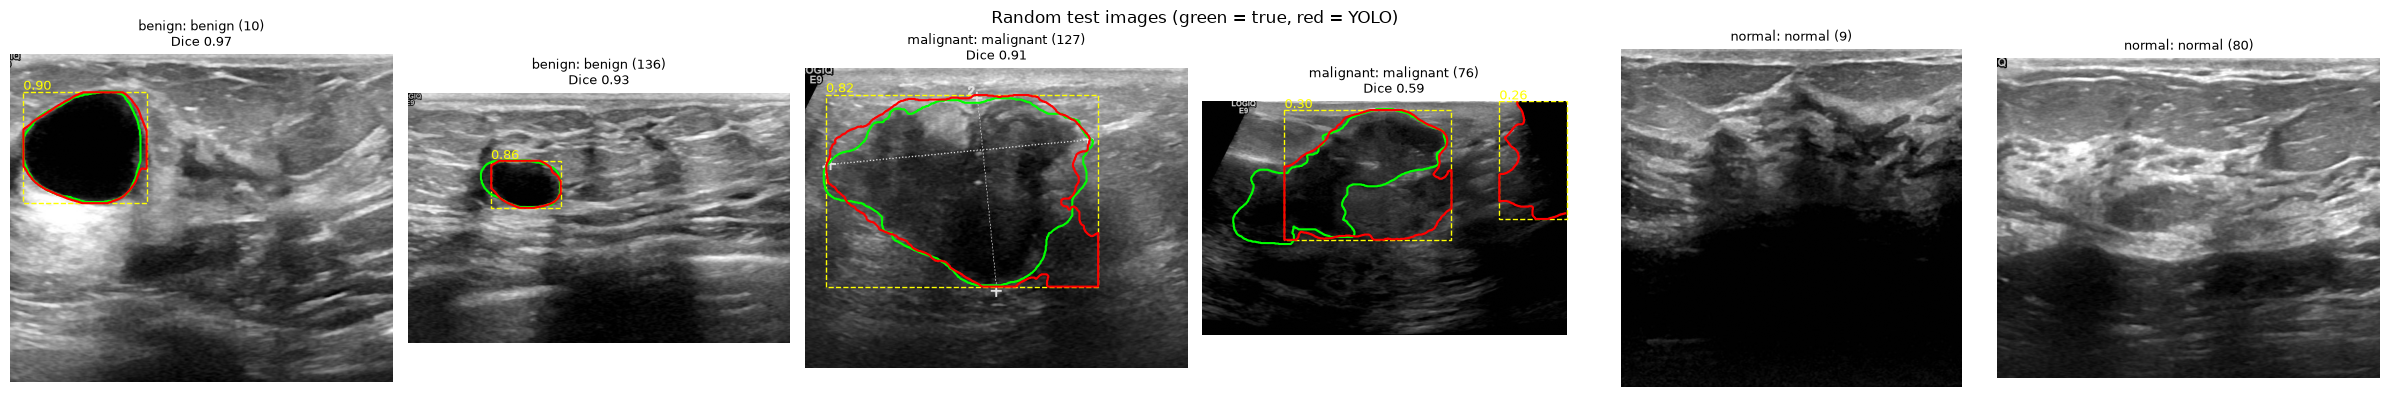

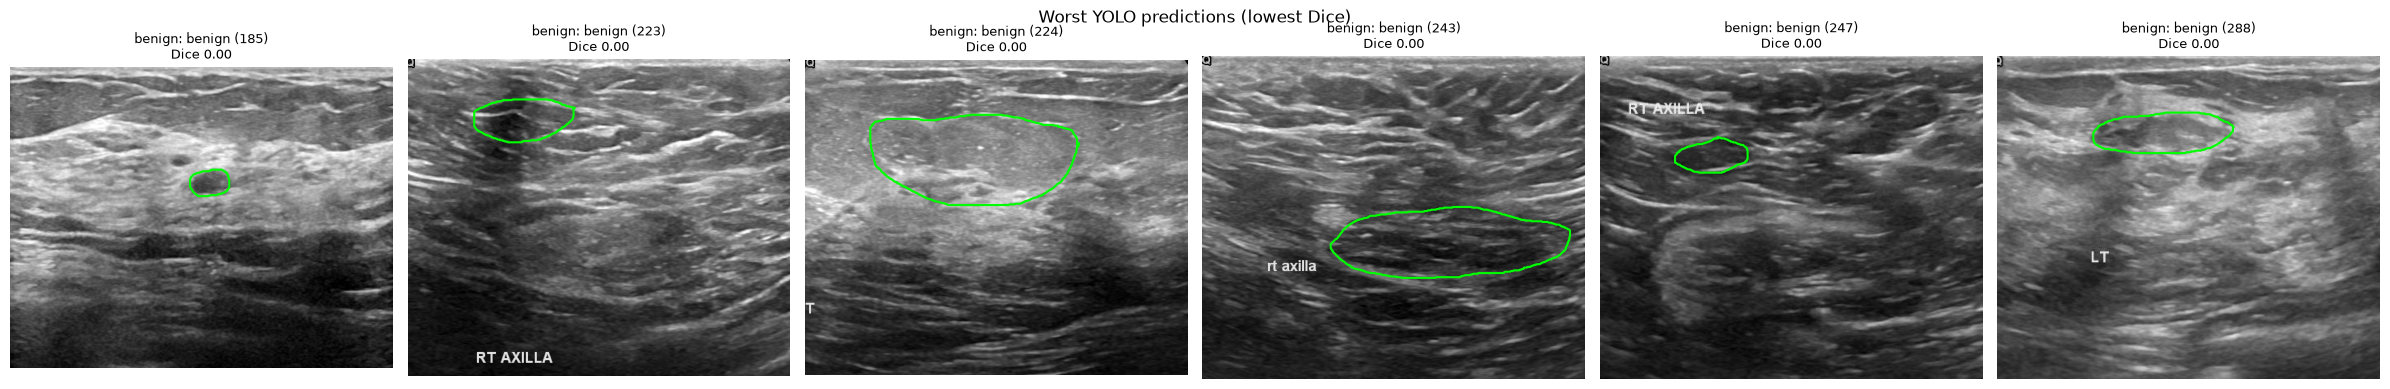

In [14]:
def show_predictions(rows, title, file_name):
    """Show test images with true outline, YOLO mask and boxes, and save the figure."""
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        image = Image.open(DATA_DIR / row.image_path).convert('L')
        truth = load_true_mask(test_df.loc[test_df['image_path'] == row.image_path, 'mask_paths'].iloc[0])
        pred = np.array(Image.open(YOLO_DIR / row.pred_mask_path)) > 127

        ax.imshow(image, cmap='gray')
        if truth.any():
            ax.contour(truth, levels=[0.5], colors='lime', linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)
        for detection in all_detections[row.image_path]:
            left, top, right, bottom = detection['box']
            ax.add_patch(patches.Rectangle((left, top), right - left, bottom - top,
                                           fill=False, edgecolor='yellow', linestyle='--', linewidth=1))
            ax.text(left, top - 4, f"{detection['confidence']:.2f}", color='yellow', fontsize=9)

        name = f'{row.label}: {Path(row.image_path).stem}'
        ax.set_title(f'{name}\nDice {row.dice:.2f}' if row.label != 'normal' else name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(YOLO_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()


examples = results.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class
show_predictions(examples, 'Random test images (green = true, red = YOLO)', 'prediction_examples.png')

worst = results[tumour].nsmallest(6, 'dice')                                             # hardest cases
show_predictions(worst, 'Worst YOLO predictions (lowest Dice)', 'worst_predictions.png')

## 7. Save the config

In [15]:
config = {
    'model_name': 'YOLO11s-seg',
    'architecture': 'yolo',
    'pretrained': PRETRAINED,
    'classes': ['lesion'],
    'image_size': IMAGE_SIZE,
    'conf_threshold': CONF_THRESHOLD_V2,                 # v2: tuned on the validation set (v1: 0.25)
    'clean_masks': CLEAN_MASKS,                          # v2: mask cleanup settings
    'min_region_pct': MIN_REGION_PCT,
    'min_lesion_pixels': MIN_LESION_PIXELS,
    'classifies_benign_malignant': False,
    'epochs_trained': int(len(history)),
    'best_epoch': int(history.loc[history['metrics/mAP50-95(M)'].idxmax(), 'epoch']),
    'batch_size': BATCH_SIZE,
    'images': manifest['split'].value_counts().to_dict(),
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M') if TRAIN else previous_config['trained_on'],   # v2
    'evaluated_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(YOLO_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "model_name": "YOLO11s-seg",
  "architecture": "yolo",
  "pretrained": "yolo11s-seg.pt",
  "classes": [
    "lesion"
  ],
  "image_size": 640,
  "conf_threshold": 0.25,
  "clean_masks": true,
  "min_region_pct": 0.2,
  "min_lesion_pixels": 50,
  "classifies_benign_malignant": false,
  "epochs_trained": 80,
  "best_epoch": 60,
  "batch_size": 8,
  "images": {
    "train": 485,
    "test": 104,
    "val": 104
  },
  "trained_on": "2026-11-11 00:54",
  "evaluated_on": "2026-11-17 00:16"
}


## 8. Check: reload and predict, the way the app will

This loads the model from the saved files alone and predicts one test image. Its mask should match the one saved in `masks/` (Dice close to 1).

In [16]:
def load_yolo(folder):
    """Load the trained YOLO model and its config."""
    config = json.loads((folder / 'config.json').read_text())
    return YOLO(folder / 'model.pt'), config


net, saved_config = load_yolo(YOLO_DIR)
sample = results[tumour].iloc[0]
mask, detections = predict_mask(net, Image.open(DATA_DIR / sample['image_path']),
                                conf=saved_config['conf_threshold'], image_size=saved_config['image_size'],
                                device='cpu', clean=saved_config['clean_masks'])      # v2: tuned threshold + cleanup
saved_mask = np.array(Image.open(YOLO_DIR / sample['pred_mask_path'])) > 127

print('Image:       ', sample['image_path'])
print('Detections:  ', detections)
print(f'Lesion pixels: {mask.sum()}')
print(f'Match with saved mask (Dice): {dice_score(mask, saved_mask):.3f}  (should be close to 1)')

Image:        benign/benign (10).png
Detections:   [{'confidence': 0.901, 'box': [23.2, 67.0, 243.7, 265.2]}]
Lesion pixels: 35050
Match with saved mask (Dice): 1.000  (should be close to 1)


## 9. Compare all the models

This table collects the latest test results of every model that has been run (v2 for all of them).

To fill in the **measurement** rows for YOLO (count accuracy, lesion F1, size and centre errors), run `04_measure.ipynb` with `MODEL = 'yolo'`, then run this cell again.

In [17]:
compare = {
    # Outline quality
    'dice_tumour_images': 'Dice (tumour images)',
    'iou_tumour_images': 'IoU (tumour images)',
    'dice_benign': 'Dice (benign)',
    'dice_malignant': 'Dice (malignant)',
    # Mistakes
    'normal_images_with_false_lesion': 'Normal images with a false lesion',
    'tumour_images_with_no_lesion_found': 'Tumour images with no lesion found',
    # Measurements (from 04_measure)
    'count_accuracy': 'Lesion count accuracy',
    'lesion_f1': 'Lesion F1',
    'median_area_error_pct': 'Median area error (%)',
    'median_centre_distance_px': 'Median centre distance (px)',
    'shape_agreement': 'Shape agreement',
    # Classification (only models that classify)
    'accuracy': 'Accuracy (normal / benign / malignant)',
    'malignant_recall': 'Malignant recall',
}

table = {}
for name in ['classifier', 'unet', 'unet_multitask', 'yolo']:
    folder = Path('outputs') / name
    scores = {}
    for file_name in ['metrics.json', 'measurement_metrics.json']:
        if (folder / file_name).exists():
            scores.update(json.loads((folder / file_name).read_text()))
    if scores:
        table[name] = scores

comparison = pd.DataFrame(table).reindex(list(compare)).rename(index=compare).astype(float).round(3)
comparison.to_csv('outputs/model_comparison.csv')
comparison

,classifier,unet_multitask,yolo
Dice (tumour images),NaN,0.770,0.750
IoU (tumour images),NaN,0.691,0.679
Dice (benign),NaN,0.781,0.777
Dice (malignant),NaN,0.747,0.701
Normal images with a false lesion,NaN,0.176,0.412
Tumour images with no lesion found,NaN,0.046,0.103
Lesion count accuracy,NaN,0.846,NaN
Lesion F1,NaN,0.800,NaN
Median area error (%),NaN,8.600,NaN
Median centre distance (px),NaN,4.950,NaN
